In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.backtest import portfolio_returns, performance, avg_pairwise_corr

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

returns = pd.read_csv(config.PROCESSED_DIR / "returns_stocks.csv", index_col=0, parse_dates=True)
bench_ret = pd.read_csv(config.PROCESSED_DIR / "returns_benchmark.csv", index_col=0, parse_dates=True)
weights = pd.read_csv(config.PROCESSED_DIR / "weights_train.csv").set_index("ticker").loc[returns.columns]

test = returns.loc[config.TEST_START:]
bench_test = (np.exp(bench_ret.iloc[:, 0].loc[config.TEST_START:]) - 1)

port = pd.DataFrame({
    "Equal weight": portfolio_returns(test, weights["equal_weight"]),
    "Min variance": portfolio_returns(test, weights["min_variance"]),
    "Max Sharpe": portfolio_returns(test, weights["max_sharpe"]),
    "NIFTY 50": bench_test,
})
print("Test window:", test.index.min().date(), "to", test.index.max().date())

results = pd.DataFrame({k: performance(v) for k, v in port.items()}).T
results.round(3)

Test window: 2023-01-02 to 2026-10-30


,cagr,volatility,sharpe,max_drawdown,final_value_of_1
Equal weight,0.124,0.120,0.492,-0.167,1.550
Min variance,0.084,0.112,0.170,-0.242,1.353
Max Sharpe,0.093,0.125,0.223,-0.202,1.395
NIFTY 50,0.067,0.127,0.012,-0.158,1.273


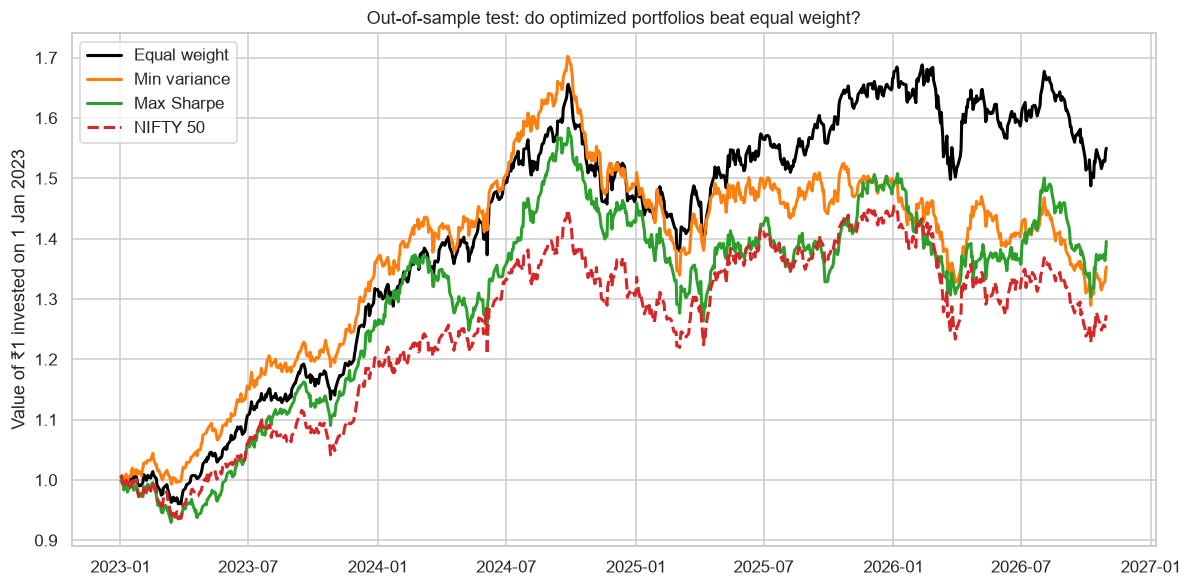

In [2]:
wealth = (1 + port).cumprod()
plt.figure(figsize=(11, 5.5))
for col, style in [("Equal weight", dict(color="black")), ("Min variance", dict(color="#ff7f0e")),
                   ("Max Sharpe", dict(color="#2ca02c")), ("NIFTY 50", dict(color="#d62728", ls="--"))]:
    plt.plot(wealth.index, wealth[col], lw=2, label=col, **style)
plt.ylabel("Value of ₹1 invested on 1 Jan 2023")
plt.title("Out-of-sample test: do optimized portfolios beat equal weight?")
plt.legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "13_backtest_growth.png", dpi=200, bbox_inches="tight")
plt.show()

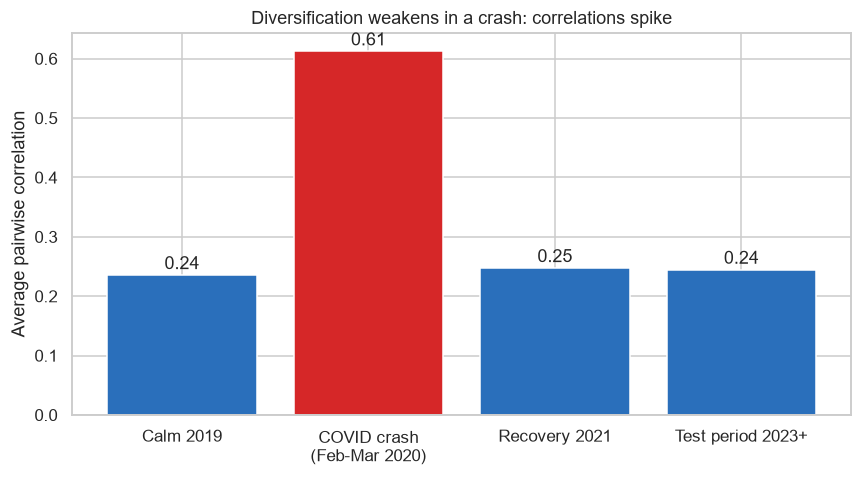

Calm 2019                      0.236
COVID crash\n(Feb-Mar 2020)    0.612
Recovery 2021                  0.247
Test period 2023+              0.245
dtype: float64


In [3]:
periods = {
    "Calm 2019": returns.loc["2019-01-01":"2019-12-31"],
    "COVID crash\n(Feb-Mar 2020)": returns.loc["2020-02-20":"2020-04-30"],
    "Recovery 2021": returns.loc["2021-01-01":"2021-12-31"],
    "Test period 2023+": test,
}
stress = pd.Series({k: avg_pairwise_corr(v) for k, v in periods.items()})

plt.figure(figsize=(8, 4.5))
bars = plt.bar(stress.index, stress.values, color=["#2a6fbb", "#d62728", "#2a6fbb", "#2a6fbb"])
for b, v in zip(bars, stress.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center")
plt.ylabel("Average pairwise correlation")
plt.title("Diversification weakens in a crash: correlations spike")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "14_stress_correlation.png", dpi=200, bbox_inches="tight")
plt.show()
print(stress.round(3))

In [6]:
results.rename_axis("portfolio").reset_index().to_csv(config.POWERBI_DIR / "backtest_results.csv", index=False)
wealth.rename_axis("date").reset_index().to_csv(config.POWERBI_DIR / "backtest_wealth.csv", index=False)

# Stress chart: numbered labels so alphabetical order = correct order
labels = ["1. Calm 2019", "2. COVID crash (Feb-Apr 2020)", "3. Recovery 2021", "4. Test period 2023+"]
stress_export = pd.DataFrame({"period": labels, "avg_correlation": stress.values})
stress_export.to_csv(config.POWERBI_DIR / "stress_correlation.csv", index=False)
print(stress_export.round(3))

print(results[["cagr", "volatility", "sharpe", "max_drawdown"]].round(3))
print("Best Sharpe out of sample:", results["sharpe"].idxmax())
print("Max Sharpe beats equal weight:", results.loc["Max Sharpe", "sharpe"] > results.loc["Equal weight", "sharpe"])
print("Min variance beats equal weight:", results.loc["Min variance", "sharpe"] > results.loc["Equal weight", "sharpe"])

                          period  avg_correlation
0                   1. Calm 2019            0.236
1  2. COVID crash (Feb-Apr 2020)            0.612
2               3. Recovery 2021            0.247
3           4. Test period 2023+            0.245
               cagr  volatility  sharpe  max_drawdown
Equal weight  0.124       0.120   0.492        -0.167
Min variance  0.084       0.112   0.170        -0.242
Max Sharpe    0.093       0.125   0.223        -0.202
NIFTY 50      0.067       0.127   0.012        -0.158
Best Sharpe out of sample: Equal weight
Max Sharpe beats equal weight: False
Min variance beats equal weight: False


## Conclusion

**The optimizers did not beat equal weight out of sample.** On 2023 onward, equal weight delivered a Sharpe ratio of **0.49**, versus **0.22** for max Sharpe and **0.17** for minimum variance. The max-Sharpe portfolio fell from **0.86** in training to **0.22** in testing, which is a typical sign of overfitting: expected returns estimated from 2019-2022 were noisy, and the optimizer concentrated in past winners. Minimum variance achieved the lowest volatility (**11.2%**) but the worst maximum drawdown (**-24.2%**), showing that low volatility does not guarantee shallow losses. All three stock portfolios beat NIFTY 50 (CAGR 8.4-12.4% vs 6.7%), though this is inflated by survivorship bias in the stock universe.

**Stress analysis:** average pairwise correlation rose from **0.24** in calm 2019 to **0.61** during the COVID crash (Feb-Apr 2020), then fell back to about **0.25**. Diversification weakens precisely when markets fall, so correlation-based risk estimates from calm periods understate crash risk.

**Limitations:** the test window is under 4 years and covers one market regime; portfolios are rebalanced daily to constant weights; transaction costs are ignored; the universe uses today's large-caps.

**Next steps:** shrinkage covariance estimates, rolling re-optimization, and ML-based return forecasting.